In [ ]:
!pip install annoy -q

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
from annoy import AnnoyIndex

SEED = 1
np.random.seed(SEED)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
TRAIN_URL = "https://raw.githubusercontent.com/EvADarya/Data_processing-DLS-/refs/heads/main/game_of_thrones_train.csv"
TEST_URL  = "https://raw.githubusercontent.com/EvADarya/Data_processing-DLS-/refs/heads/main/game_of_thrones_test.csv"

train_raw = pd.read_csv(TRAIN_URL)
test_raw  = pd.read_csv(TEST_URL)

def preprocess_for_annoy(train, test, seed=1):
    """Упрощённая предобработка, сохраняющая name."""
    train = train.copy()
    test = test.copy()

    # Сохраняем имена
    train_names = train['name'].values
    test_names = test['name'].values if 'name' in test.columns else None

    # Помечаем источник
    train['_is_train'] = 1
    test['_is_train'] = 0
    if 'isAlive' not in test.columns:
        test['isAlive'] = np.nan

    df = pd.concat([train, test], ignore_index=True)

    # Удаляем «утечные» и служебные колонки
    for c in ['S.No', 'title', 'father', 'mother', 'spouse', 'heir',
              'successor', 'allegiance', 'books', 'actor', 'siblings']:
        if c in df.columns:
            df = df.drop(columns=[c])

    # age
    if 'age' in df.columns:
        df['age'] = pd.to_numeric(df['age'], errors='coerce')
        df['age'] = df['age'].fillna(df['age'].median())

    # dateOfBirth
    if 'dateOfBirth' in df.columns:
        df['dateOfBirth'] = pd.to_datetime(df['dateOfBirth'], errors='coerce')
        df['birth_year'] = df['dateOfBirth'].dt.year
        df['birth_year'] = df['birth_year'].fillna(df['birth_year'].median())
        df = df.drop(columns=['dateOfBirth'])

    # culture
    if 'culture' in df.columns:
        df['culture'] = df['culture'].fillna('no_data')
        le_culture = LabelEncoder()
        df['culture_enc'] = le_culture.fit_transform(df['culture'].astype(str))
        df = df.drop(columns=['culture'])

    # house
    if 'house' in df.columns:
        df['house'] = df['house'].fillna('no_data')
        le_house = LabelEncoder()
        df['house_enc'] = le_house.fit_transform(df['house'].astype(str))
        df = df.drop(columns=['house'])

    # popularity
    if 'popularity' in df.columns:
        df['popularity'] = pd.to_numeric(df['popularity'], errors='coerce').fillna(0)
        M = 100  # вариант 1
        df['popularity'] = np.log1p(df['popularity'] * M + 1)

    # name удалим только после разделения
    if 'name' in df.columns:
        df = df.drop(columns=['name'])

    # One-hot для оставшихся object-колонок
    obj_cols = df.select_dtypes(include=['object']).columns.tolist()
    if obj_cols:
        df = pd.get_dummies(df, columns=obj_cols, drop_first=True)

    # Разделяем
    train_df = df[df['_is_train'] == 1].copy().drop(columns=['_is_train'])
    test_df  = df[df['_is_train'] == 0].copy().drop(columns=['_is_train'])

    y_train = train_df['isAlive'].astype(int).values
    X_train = train_df.drop(columns=['isAlive'])
    X_test  = test_df.drop(columns=['isAlive'])

    # Чистка NaN/inf
    X_train = X_train.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    X_test  = X_test.replace([np.inf, -np.inf], np.nan).fillna(0.0)

    # Согласование колонок
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0.0)

    # Масштабирование
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled  = scaler.transform(X_test)

    return (X_train_scaled, y_train, X_test_scaled,
            train_names, test_names, X_train.columns.tolist())

X_train, y_train, X_test, train_names, test_names, feature_names = preprocess_for_annoy(
    train_raw, test_raw, seed=SEED
)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Признаки: {feature_names[:5]} ...")

X_train: (1557, 18), X_test: (389, 18)
Признаки: ['male', 'book1', 'book2', 'book3', 'book4'] ...


In [ ]:
VARIANT = 1
CONFIG = {
    'n_trees': 5,
    'n_neighbors_ann': 5,
    'query_character': 'Jon Snow',
    'metric_annoy': 'euclidean',
}

# Поиск индекса query_character
query_idx = None
for i, name in enumerate(train_names):
    if name == CONFIG['query_character']:
        query_idx = i
        break

if query_idx is None:
    # Если точного совпадения нет — берём ближайшего по алфавиту
    sorted_names = sorted(enumerate(train_names), key=lambda x: x[1])
    # Простой эвристический выбор: первое имя, содержащее фамилию
    candidate = [i for i, n in enumerate(train_names) if 'Snow' in str(n)]
    if candidate:
        query_idx = candidate[0]
    else:
        query_idx = 0
    print(f"Внимание: '{CONFIG['query_character']}' не найден. "
          f"Используется '{train_names[query_idx]}' (idx={query_idx}).")
else:
    print(f"Персонаж найден: '{train_names[query_idx]}' (idx={query_idx})")

query_vector = X_train[query_idx]
query_label = y_train[query_idx]
print(f"Вектор запроса: размерность {query_vector.shape[0]}, метка isAlive={query_label}")

Внимание: 'Jon Snow' не найден. Используется 'Larence Snow' (idx=1154).
Вектор запроса: размерность 18, метка isAlive=1


In [ ]:
n_dim = X_train.shape[1]
n_trees = CONFIG['n_trees']
metric = CONFIG['metric_annoy']
n_neighbors = CONFIG['n_neighbors_ann']

annoy_index = AnnoyIndex(n_dim, metric)
annoy_index.set_seed(SEED)

for i in range(X_train.shape[0]):
    annoy_index.add_item(i, X_train[i].astype(np.float32).tolist())

t0 = time.perf_counter()
annoy_index.build(n_trees)
build_time = time.perf_counter() - t0
print(f"Индекс построен: n_trees={n_trees}, время={build_time:.4f} с")

# Поиск через Annoy (используем вектор запроса)
t0 = time.perf_counter()
annoy_neighbors = annoy_index.get_nns_by_vector(
    query_vector.astype(np.float32).tolist(),
    n_neighbors,
    include_distances=False
)
annoy_time = time.perf_counter() - t0
print(f"ANN соседи: {annoy_neighbors}")
print(f"Время ANN-поиска: {annoy_time:.6f} с")

Индекс построен: n_trees=5, время=0.0062 с
ANN соседи: [1154, 1049, 1454, 1432, 1096]
Время ANN-поиска: 0.000137 с


In [ ]:
# Точный поиск через sklearn
exact_index = NearestNeighbors(n_neighbors=n_neighbors, metric=metric)
exact_index.fit(X_train)

t0 = time.perf_counter()
exact_distances, exact_indices = exact_index.kneighbors([query_vector])
exact_time = time.perf_counter() - t0
exact_neighbors = exact_indices[0].tolist()

print(f"Точные соседи: {exact_neighbors}")
print(f"Время точного поиска: {exact_time:.6f} с")

# Recall@k = |ANN_top_k ∩ exact_top_k| / k
intersection = set(annoy_neighbors) & set(exact_neighbors)
recall = len(intersection) / n_neighbors
print(f"Пересечение: {sorted(intersection)}")
print(f"recall@{n_neighbors} = {recall:.4f}")

Точные соседи: [1154, 1049, 223, 1454, 1432]
Время точного поиска: 0.021977 с
Пересечение: [1049, 1154, 1432, 1454]
recall@5 = 0.8000


n_trees=  1: recall=0.4000, build=0.0028s, query=0.000022s
n_trees=  2: recall=0.8000, build=0.0015s, query=0.000018s
n_trees=  5: recall=0.8000, build=0.0035s, query=0.000015s
n_trees= 10: recall=1.0000, build=0.0063s, query=0.000022s
n_trees= 20: recall=1.0000, build=0.0122s, query=0.000044s
n_trees= 50: recall=1.0000, build=0.0547s, query=0.000100s
n_trees=100: recall=1.0000, build=0.0995s, query=0.000125s


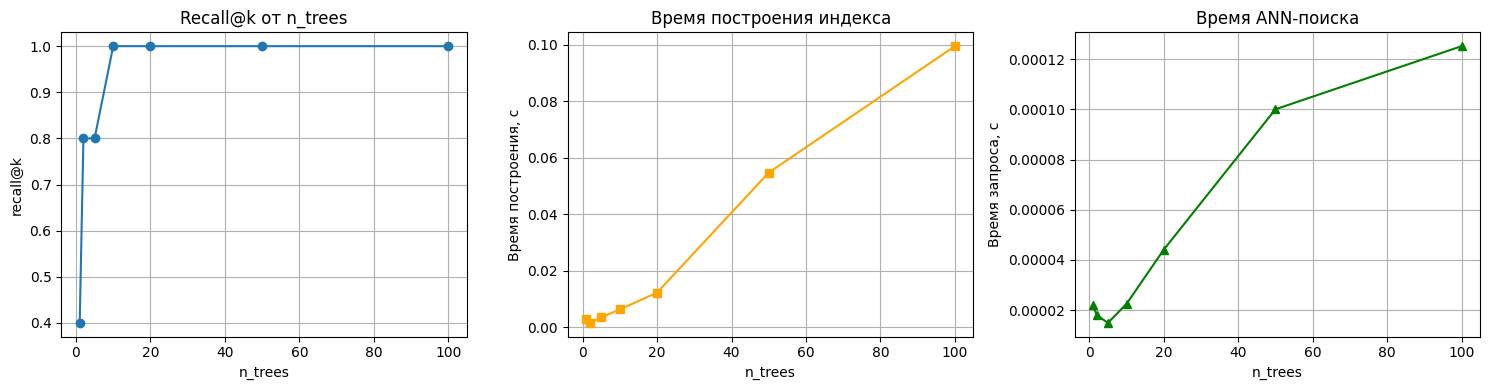

In [ ]:
tree_values = [1, 2, 5, 10, 20, 50, 100]
recalls = []
times_ann = []
build_times = []

# Точные соседи уже известны
exact_set = set(exact_neighbors)

for nt in tree_values:
    idx = AnnoyIndex(n_dim, metric)
    idx.set_seed(SEED)
    for i in range(X_train.shape[0]):
        idx.add_item(i, X_train[i].astype(np.float32).tolist())

    t0 = time.perf_counter()
    idx.build(nt)
    bt = time.perf_counter() - t0
    build_times.append(bt)

    t0 = time.perf_counter()
    ann_nn = idx.get_nns_by_vector(
        query_vector.astype(np.float32).tolist(),
        n_neighbors,
        include_distances=False
    )
    at = time.perf_counter() - t0
    times_ann.append(at)

    rec = len(set(ann_nn) & exact_set) / n_neighbors
    recalls.append(rec)
    print(f"n_trees={nt:3d}: recall={rec:.4f}, build={bt:.4f}s, query={at:.6f}s")

# Графики
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(tree_values, recalls, marker='o')
axes[0].set_xlabel('n_trees')
axes[0].set_ylabel('recall@k')
axes[0].set_title('Recall@k от n_trees')
axes[0].grid(True)

axes[1].plot(tree_values, build_times, marker='s', color='orange')
axes[1].set_xlabel('n_trees')
axes[1].set_ylabel('Время построения, с')
axes[1].set_title('Время построения индекса')
axes[1].grid(True)

axes[2].plot(tree_values, times_ann, marker='^', color='green')
axes[2].set_xlabel('n_trees')
axes[2].set_ylabel('Время запроса, с')
axes[2].set_title('Время ANN-поиска')
axes[2].grid(True)

plt.tight_layout()
plt.savefig('annoy_n_trees_effect.png', dpi=150)
plt.show()

In [ ]:
# Обучаем kNN на train (как в основном пайплайне)
knn = KNeighborsClassifier(n_neighbors=n_neighbors, metric=metric)
knn.fit(X_train, y_train)

# Предсказания на тесте (точный поиск)
y_pred_exact = knn.predict(X_test)
acc_exact = accuracy_score(y_test_labels, y_pred_exact) if 'y_test_labels' in globals() else None

# Для оценки f1 на валидационной части:
# Разделим train на train/val (стратифицированно)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)

knn_val = KNeighborsClassifier(n_neighbors=n_neighbors, metric=metric)
knn_val.fit(X_tr, y_tr)
pred_exact_val = knn_val.predict(X_val)
f1_exact = f1_score(y_val, pred_exact_val)

# kNN на соседях, найденных через Annoy: для каждого val-объекта ищем соседей в X_tr через Annoy
# Строим Annoy на X_tr
idx_val = AnnoyIndex(n_dim, metric)
idx_val.set_seed(SEED)
for i in range(X_tr.shape[0]):
    idx_val.add_item(i, X_tr[i].astype(np.float32).tolist())
idx_val.build(n_trees)

pred_ann = []
for v in X_val:
    nn_idx = idx_val.get_nns_by_vector(v.astype(np.float32).tolist(), n_neighbors)
    nn_labels = y_tr[nn_idx]
    # мажоритарное голосование
    pred_ann.append(1 if np.sum(nn_labels) >= 0.5 * len(nn_labels) else 0)
pred_ann = np.array(pred_ann)
f1_ann = f1_score(y_val, pred_ann)

print(f"Точный kNN: accuracy={accuracy_score(y_val, pred_exact_val):.4f}, f1={f1_exact:.4f}")
print(f"kNN на ANN-соседях: accuracy={accuracy_score(y_val, pred_ann):.4f}, f1={f1_ann:.4f}")

Точный kNN: accuracy=0.8397, f1=0.9031
kNN на ANN-соседях: accuracy=0.8365, f1=0.9017


In [ ]:
print("ИТОГИ ЧАСТИ 6 (ANN / Annoy)")
print(f"Метрика: {metric}")
print(f"n_trees (вариант): {n_trees}")
print(f"n_neighbors_ann (вариант): {n_neighbors}")
print(f"query_character: {CONFIG['query_character']} (idx={query_idx})")
print()
print(f"Recall@{n_neighbors} при n_trees={n_trees}: {recall:.4f}")
print(f"Время ANN-поиска: {annoy_time:.6f} с")
print(f"Время точного поиска: {exact_time:.6f} с")
print(f"Ускорение: {exact_time / annoy_time:.2f}x" if annoy_time > 0 else "Ускорение: n/a")
print()
print(f"kNN (точный) на валидации: f1={f1_exact:.4f}")
print(f"kNN (ANN-соседи) на валидации: f1={f1_ann:.4f}")

ИТОГИ ЧАСТИ 6 (ANN / Annoy)
Метрика: euclidean
n_trees (вариант): 5
n_neighbors_ann (вариант): 5
query_character: Jon Snow (idx=1154)

Recall@5 при n_trees=5: 0.8000
Время ANN-поиска: 0.000137 с
Время точного поиска: 0.021977 с
Ускорение: 160.28x

kNN (точный) на валидации: f1=0.9031
kNN (ANN-соседи) на валидации: f1=0.9017
